# EDA dữ liệu văn bản pháp luật tiếng Việt

Đây là **bản trình bày** của phase EDA. Thống kê gốc do `scripts/eda.py` sinh; notebook chỉ đọc CSV trong `reports/data_stats/` và xuất biểu đồ. Notebook không đọc HTML thô và không thay thế pipeline.

Phạm vi mô tả chính: `Luật`, `Nghị định`, `Thông tư` có trạng thái `Còn hiệu lực`. Số Điều ở đây là ước lượng regex, chưa phải kết quả parse.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import yaml

def find_root(start):
    for path in [start.resolve(), *start.resolve().parents]:
        if (path / 'configs' / 'data.yaml').exists():
            return path
    raise FileNotFoundError('Không tìm thấy configs/data.yaml')

ROOT = find_root(Path.cwd())
STATS = ROOT / 'reports' / 'data_stats'
FIGURES = ROOT / 'reports' / 'figures' / 'eda'
FIGURES.mkdir(parents=True, exist_ok=True)
with (ROOT / 'configs' / 'data.yaml').open(encoding='utf-8') as f:
    config = yaml.safe_load(f)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180, 'font.family': 'DejaVu Sans', 'axes.titleweight': 'bold'})
C = {'navy': '#173F5F', 'blue': '#20639B', 'teal': '#3CAEA3', 'gold': '#F6D55C', 'red': '#ED553B'}
def load(name): return pd.read_csv(STATS / name, encoding='utf-8-sig')
def save(fig, name): fig.savefig(FIGURES / name, bbox_inches='tight', facecolor='white')

pd.DataFrame({'Thông tin': ['Dataset', 'Revision', 'Seed', 'Nguồn bảng'], 'Giá trị': [config['dataset']['name'], config['dataset']['revision'], config['seed'], str(STATS.relative_to(ROOT))]})

,Thông tin,Giá trị
0,Dataset,th1nhng0/vietnamese-legal-documents
1,Revision,8977887f17be2defae4c5171d55562e1cde7d695
2,Seed,42
3,Nguồn bảng,reports\data_stats


## 1. Quy mô và phạm vi

Ba phạm vi dưới đây phải được gọi đúng tên khi báo cáo: toàn bộ metadata, tập mô tả theo loại/hiệu lực, và 8 lĩnh vực đã chốt ở OI-10.

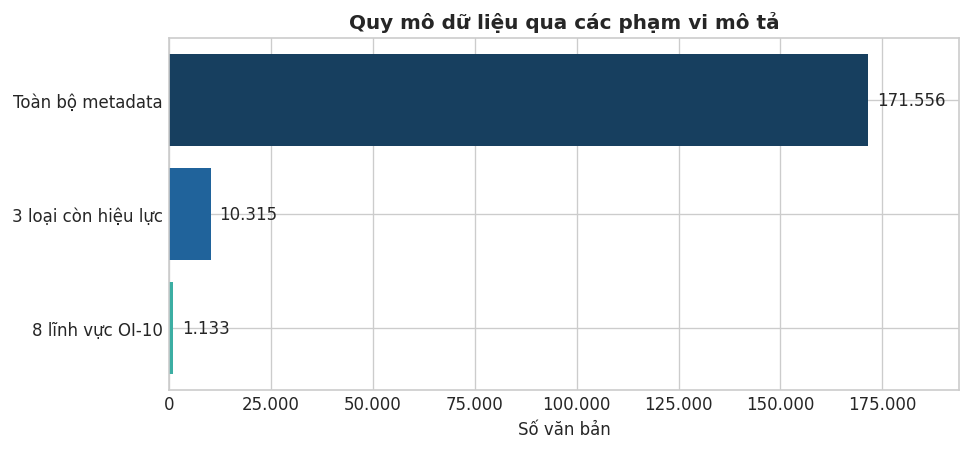

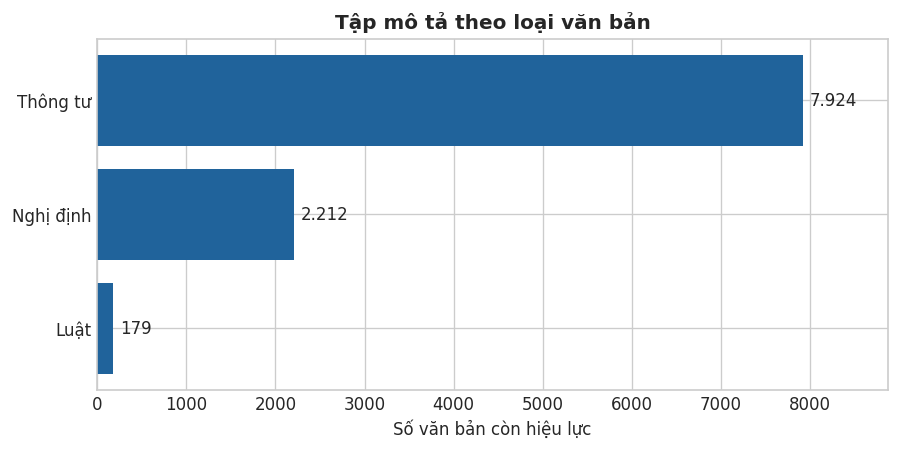

,Phạm vi,Số văn bản
0,Toàn bộ metadata,171556
1,3 loại còn hiệu lực,10315
2,8 lĩnh vực OI-10,1133


In [2]:
doc_types = load('doc_type_counts.csv')
core_types = load('core_effective_by_type.csv')
domains = load('domain_counts_core_effective.csv')
selected = domains[domains['linh_vuc'].isin(config['filter']['domains'])].sort_values(['n_docs', 'linh_vuc'], ascending=[False, True])
assert set(selected['linh_vuc']) == set(config['filter']['domains'])
scope = pd.DataFrame({'Phạm vi': ['Toàn bộ metadata', '3 loại còn hiệu lực', '8 lĩnh vực OI-10'], 'Số văn bản': [doc_types.n_docs.sum(), core_types.n_docs.sum(), selected.n_docs.sum()]})
fig, ax = plt.subplots(figsize=(8.5, 3.8))
bars = ax.barh(scope['Phạm vi'][::-1], scope['Số văn bản'][::-1], color=[C['teal'], C['blue'], C['navy']])
ax.bar_label(bars, labels=[f'{int(v):,}'.replace(',', '.') for v in scope['Số văn bản'][::-1]], padding=5)
ax.set(title='Quy mô dữ liệu qua các phạm vi mô tả', xlabel='Số văn bản', xlim=(0, scope['Số văn bản'].max() * 1.13))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'.replace(',', '.')))
save(fig, '01_scope_funnel.png'); plt.show()

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ordered = core_types.sort_values('n_docs')
bars = ax.barh(ordered.loai_van_ban, ordered.n_docs, color=C['blue'])
ax.bar_label(bars, labels=[f'{int(v):,}'.replace(',', '.') for v in ordered.n_docs], padding=4)
ax.set(title='Tập mô tả theo loại văn bản', xlabel='Số văn bản còn hiệu lực', xlim=(0, ordered.n_docs.max() * 1.12))
save(fig, '02_core_document_types.png'); plt.show()
scope

## 2. Chất lượng nội dung

`missing_row` là metadata không có dòng content; `empty_text` là HTML có mặt nhưng sau khi bỏ tag thô không còn chữ. Đây là kiểm tra EDA, chưa thay bước parse/validate.

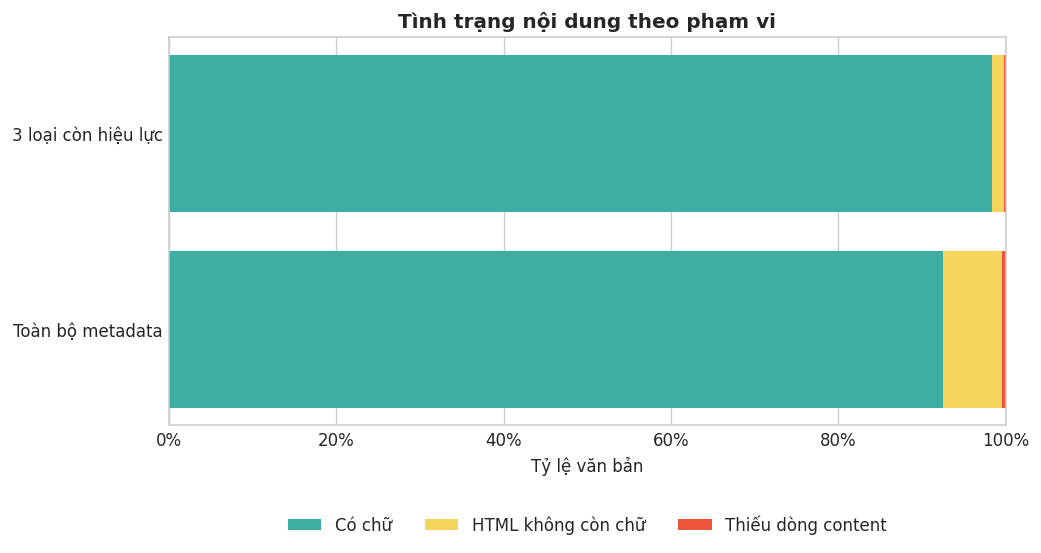

,scope,content_state,n_docs,pct
0,all,ok,158774,92.549
1,all,empty_text,12050,7.024
2,all,missing_row,732,0.427
3,core_effective,ok,10147,98.371
4,core_effective,empty_text,150,1.454
5,core_effective,missing_row,18,0.175


In [3]:
content = load('content_missing_empty.csv')
pivot = content.pivot(index='scope', columns='content_state', values='pct').reindex(['all', 'core_effective']).fillna(0)
states = [('ok', 'Có chữ', C['teal']), ('empty_text', 'HTML không còn chữ', C['gold']), ('missing_row', 'Thiếu dòng content', C['red'])]
fig, ax = plt.subplots(figsize=(9, 4.2)); left = pd.Series(0.0, index=pivot.index)
for key, label, color in states:
    if key in pivot.columns:
        ax.barh(pivot.index, pivot[key], left=left, label=label, color=color); left += pivot[key]
ax.set_yticks([0, 1], ['Toàn bộ metadata', '3 loại còn hiệu lực'])
ax.set(title='Tình trạng nội dung theo phạm vi', xlabel='Tỷ lệ văn bản', xlim=(0, 100))
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=3, frameon=False)
save(fig, '03_content_completeness.png'); plt.show()
content

## 3. Tám lĩnh vực đã chốt

Tên lĩnh vực giữ đúng chuỗi gốc. Số văn bản và số Điều ước lượng được đặt cạnh nhau vì phản ánh hai khía cạnh khác nhau; ước lượng regex không phải số Điều sau parse.

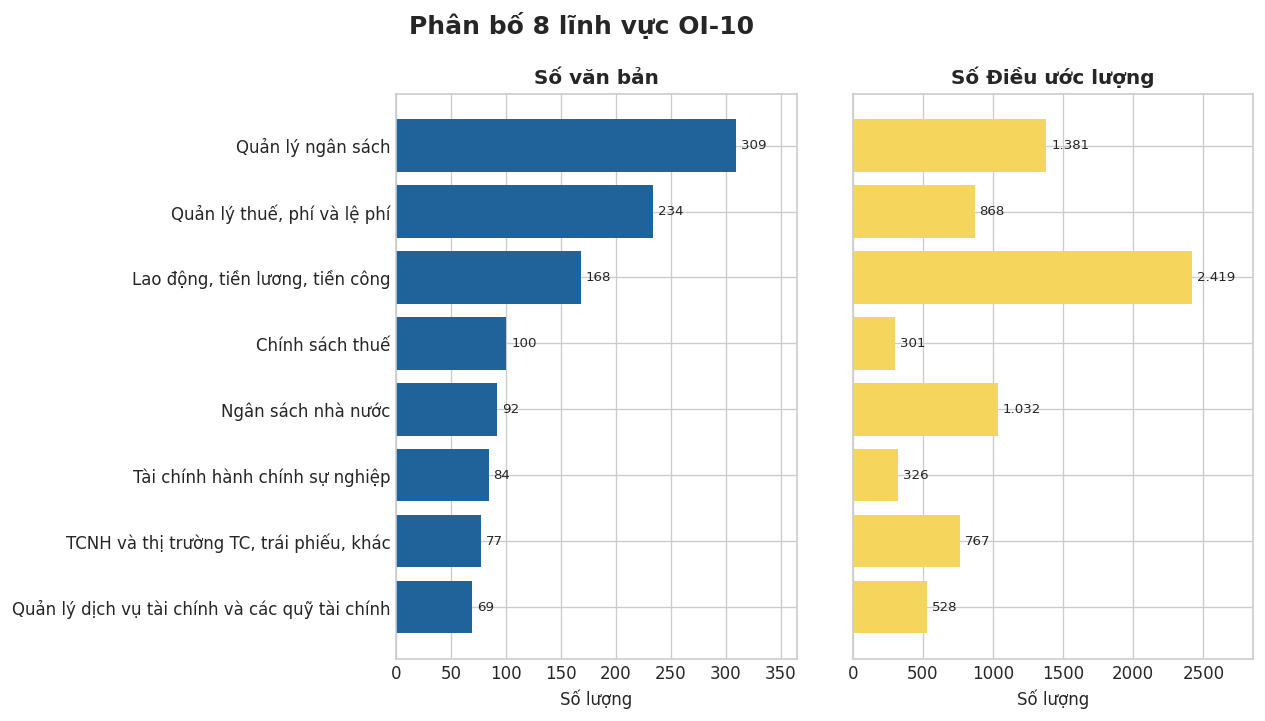

,linh_vuc,n_docs,n_luat,n_nghi_dinh,n_thong_tu,est_articles_line_start
0,Quản lý ngân sách,309,0,0,309,1381
1,"Quản lý thuế, phí và lệ phí",234,0,0,234,868
2,"Lao động, tiền lương, tiền công",168,1,27,140,2419
3,Chính sách thuế,100,0,13,87,301
4,Ngân sách nhà nước,92,0,16,76,1032
5,Tài chính hành chính sự nghiệp,84,0,0,84,326
6,"TCNH và thị trường TC, trái phiếu, khác",77,0,0,77,767
7,Quản lý dịch vụ tài chính và các quỹ tài chính,69,0,0,69,528


In [4]:
plot_domains = selected.sort_values('n_docs')
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True)
for ax, column, title, color in [(axes[0], 'n_docs', 'Số văn bản', C['blue']), (axes[1], 'est_articles_line_start', 'Số Điều ước lượng', C['gold'])]:
    bars = ax.barh(plot_domains.linh_vuc, plot_domains[column], color=color)
    ax.bar_label(bars, labels=[f'{int(v):,}'.replace(',', '.') for v in plot_domains[column]], padding=3, fontsize=8)
    ax.set(title=title, xlabel='Số lượng', xlim=(0, plot_domains[column].max() * 1.18))
fig.suptitle('Phân bố 8 lĩnh vực OI-10', fontsize=15, fontweight='bold'); fig.subplots_adjust(left=0.39, wspace=0.14, top=0.87)
save(fig, '04_selected_domains.png'); plt.show()
selected[['linh_vuc', 'n_docs', 'n_luat', 'n_nghi_dinh', 'n_thong_tu', 'est_articles_line_start']].reset_index(drop=True)

## 4. Quan hệ giữa văn bản

EDA có 31 nhãn gốc. Biểu đồ trái mô tả các nhãn lớn nhất; biểu đồ phải tập trung vào 6 nhãn đã chốt để gom họ. Tỷ lệ ánh xạ thấp không đồng nghĩa cạnh bị xóa; cách xử lý ID thiếu nằm trong SPEC.

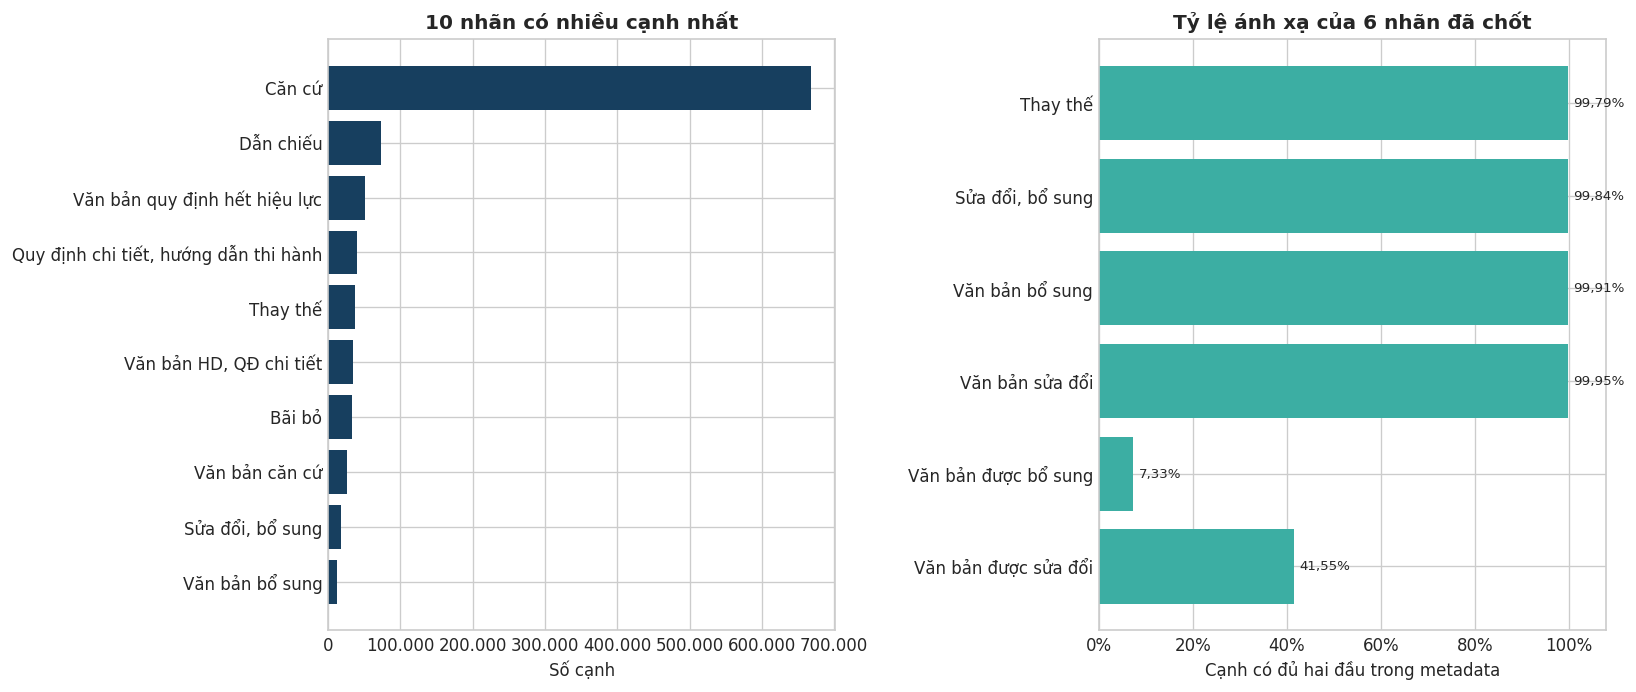

,relationship,n_edges,n_both_mapped,pct_both_mapped
0,Thay thế,37146,37068,99.79
1,"Sửa đổi, bổ sung",17674,17645,99.84
2,Văn bản bổ sung,12853,12841,99.91
3,Văn bản sửa đổi,7466,7462,99.95
4,Văn bản được bổ sung,532,39,7.33
5,Văn bản được sửa đổi,284,118,41.55


In [5]:
relations = load('relationship_types.csv')
approved = relations[relations.relationship.isin(config['relations']['mapping'])].sort_values('n_edges')
assert set(approved.relationship) == set(config['relations']['mapping'])
top_rel = relations.nlargest(10, 'n_edges').sort_values('n_edges')
fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
axes[0].barh(top_rel.relationship, top_rel.n_edges, color=C['navy']); axes[0].set(title='10 nhãn có nhiều cạnh nhất', xlabel='Số cạnh')
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'.replace(',', '.')))
bars = axes[1].barh(approved.relationship, approved.pct_both_mapped, color=C['teal'])
axes[1].bar_label(bars, labels=[f'{v:.2f}%'.replace('.', ',') for v in approved.pct_both_mapped], padding=3, fontsize=8)
axes[1].set(title='Tỷ lệ ánh xạ của 6 nhãn đã chốt', xlabel='Cạnh có đủ hai đầu trong metadata', xlim=(0, 108))
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter()); fig.subplots_adjust(left=0.25, right=0.96, wspace=0.52, top=0.88)
save(fig, '05_relationships.png'); plt.show()
approved[['relationship', 'n_edges', 'n_both_mapped', 'pct_both_mapped']].sort_values('n_edges', ascending=False).reset_index(drop=True)

## 5. Độ dài và cảnh báo cho bước tiếp theo

Độ dài là số ký tự sau khi bỏ tag thô, không phải token E5. Không tìm thấy `Điều <số>` ở đầu dòng là tín hiệu cần kiểm tra parser, không chứng minh văn bản thật sự không có Điều.

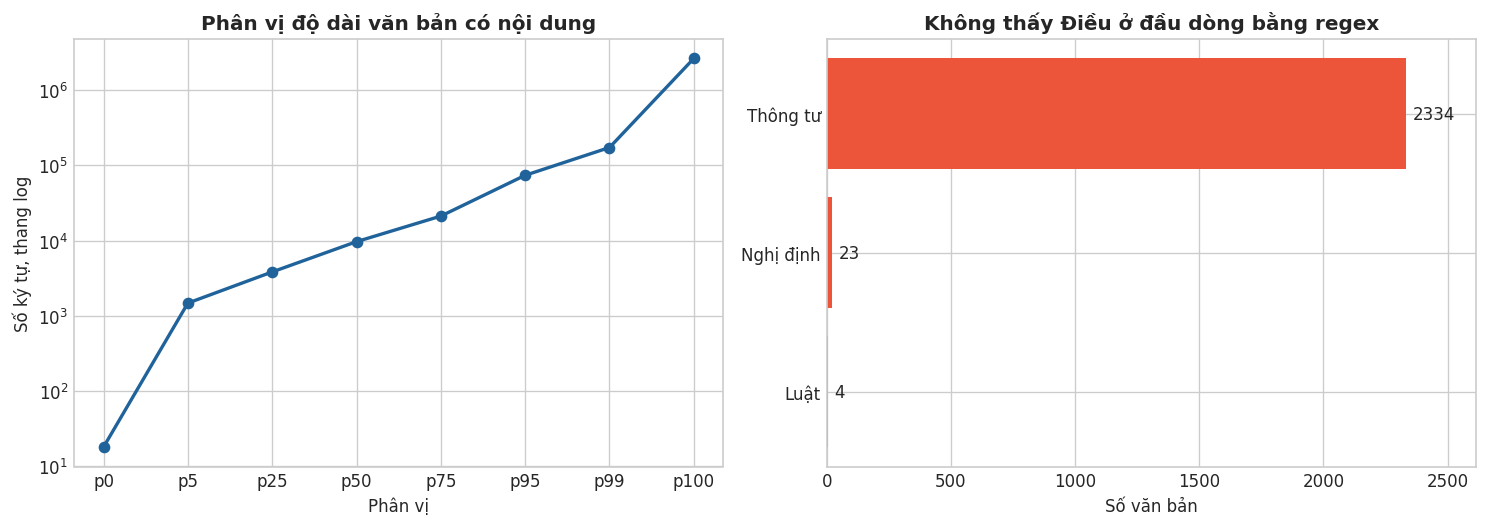

,quantile,html_chars,text_chars
0,p0,373,18
1,p5,5384,1474
2,p25,10248,3824
3,p50,22289,9656
4,p75,51228,21118
5,p95,213213,73560
6,p99,668420,172121
7,p100,12756339,2627048


In [6]:
lengths = load('length_quantiles_core_effective.csv')
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].plot(lengths['quantile'], lengths.text_chars, marker='o', color=C['blue'], linewidth=2)
axes[0].set_yscale('log'); axes[0].set(title='Phân vị độ dài văn bản có nội dung', xlabel='Phân vị', ylabel='Số ký tự, thang log')
zero = core_types.sort_values('docs_zero_article_line_start')
bars = axes[1].barh(zero.loai_van_ban, zero.docs_zero_article_line_start, color=C['red']); axes[1].bar_label(bars, padding=4)
axes[1].set(title='Không thấy Điều ở đầu dòng bằng regex', xlabel='Số văn bản', xlim=(0, zero.docs_zero_article_line_start.max() * 1.12))
fig.tight_layout(); save(fig, '06_length_and_article_estimate.png'); plt.show()
lengths

## 6. Kết luận EDA

- Dataset gốc lớn hơn nhiều so với phạm vi corpus; báo cáo phải ghi rõ phạm vi của từng số.
- Nội dung thiếu/rỗng và số Điều regex bằng 0 là tín hiệu cho bước parse/validate xử lý và ghi log.
- EDA giữ nguyên tên lĩnh vực và nhãn quan hệ; quyết định OI-10 nằm trong SPEC/config.
- Hình được xuất vào `reports/figures/eda/`; CSV chi tiết vẫn được giữ để kiểm tra và tái lập.

**Giới hạn:** bóc tag và regex chỉ phục vụ mô tả. Notebook không thay kết quả parse, validate hay split.